# 05 — Threshold Tuning & Final Test Evaluation

**Goal:**
1. Take the winning config from `04`.
2. Choose the decision threshold using **out-of-fold predictions on the training set** — never the test set.
3. Train the final model on the full training set and evaluate it **once** on the untouched test set.

Why not just use 0.5? The threshold is a *business* decision. Missing a fraud (FN) and blocking a good customer (FP) have very different costs, and 0.5 ignores that.

In [1]:
import sys
sys.path.append("..")   # so `src` is importable from notebooks/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

import json, joblib
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score, ConfusionMatrixDisplay

from src.config import REPORTS_DIR, FIGURES_DIR, MODELS_DIR
from src.utils import load_splits, make_experiment, metrics_at_threshold, get_cv

X_train, X_test, y_train, y_test = load_splits()
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

with open(REPORTS_DIR / "04_best_config.json") as f:
    best_config = json.load(f)
best_config

{'model': 'XGBoost',
 'technique': 'None',
 'cv_pr_auc': 0.855963358682866,
 'cv_pr_auc_std': 0.03395235690305251}

## 1. Out-of-fold probabilities on the training set

`cross_val_predict` gives every training row a fraud probability from a model that **did not** see that row. That's an honest stand-in for unseen data, so we can tune the threshold on it without touching the test set.

In [2]:
pipe = make_experiment(best_config["model"], best_config["technique"], pos_weight=pos_weight)
oof_proba = cross_val_predict(pipe, X_train, y_train, cv=get_cv(), method="predict_proba")[:, 1]
print(f"OOF PR-AUC: {average_precision_score(y_train, oof_proba):.4f}")

OOF PR-AUC: 0.8542


## 2. Three ways to pick a threshold

| Strategy | Rule | When it fits |
|---|---|---|
| **Max F1** | Threshold with the best balance of precision and recall | No cost information available |
| **Min cost** | Minimise `FN × cost_FN + FP × cost_FP` | You can estimate what each error costs |
| **Recall target** | Highest precision while still catching ≥ X% of fraud | The business sets a "catch at least X%" rule |

**Cost assumptions (edit these!):** a missed fraud costs the bank the stolen amount plus chargeback handling — call it **€100**. A false alarm costs an analyst review / customer call — call it **€5**. These are illustrative numbers, not from the dataset.

In [3]:
COST_FN = 100   # euros lost per missed fraud (assumption)
COST_FP = 5     # euros per false alarm (assumption)
RECALL_TARGET = 0.85

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
precision, recall = precision[:-1], recall[:-1]   # align with thresholds

# 1) Max F1
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
thr_f1 = thresholds[np.argmax(f1)]

# 2) Min cost (evaluate on a grid of thresholds)
grid_thr = np.unique(np.round(np.concatenate([np.linspace(0.001, 0.999, 999), [0.5]]), 4))
n_pos = y_train.sum()
costs = []
for t in grid_thr:
    pred = oof_proba >= t
    fn = ((~pred) & (y_train == 1)).sum()
    fp = (pred & (y_train == 0)).sum()
    costs.append(fn * COST_FN + fp * COST_FP)
costs = np.array(costs)
thr_cost = grid_thr[np.argmin(costs)]

# 3) Recall target: highest threshold that still reaches the target recall
ok = recall >= RECALL_TARGET
thr_recall = thresholds[ok].max() if ok.any() else thresholds.min()

candidates = {"Default (0.5)": 0.5, "Max F1": thr_f1, "Min cost": thr_cost,
              f"Recall ≥ {RECALL_TARGET:.0%}": thr_recall}
oof_table = pd.DataFrame(
    [{"strategy": k, **metrics_at_threshold(y_train, oof_proba, v)} for k, v in candidates.items()]
).set_index("strategy")
oof_table["cost_€"] = oof_table["FN"] * COST_FN + oof_table["FP"] * COST_FP
oof_table[["threshold", "precision", "recall", "f1", "TP", "FP", "FN", "cost_€"]]

,threshold,precision,recall,f1,TP,FP,FN,cost_€
strategy,,,,,,,,
Default (0.5),0.5000,0.9492,0.7910,0.8629,299,16,79,7980
Max F1,0.2571,0.9367,0.8228,0.8761,311,21,67,6805
Min cost,0.0350,0.8529,0.8439,0.8484,319,55,59,6175
Recall ≥ 85%,0.0127,0.7318,0.8519,0.7873,322,118,56,6190


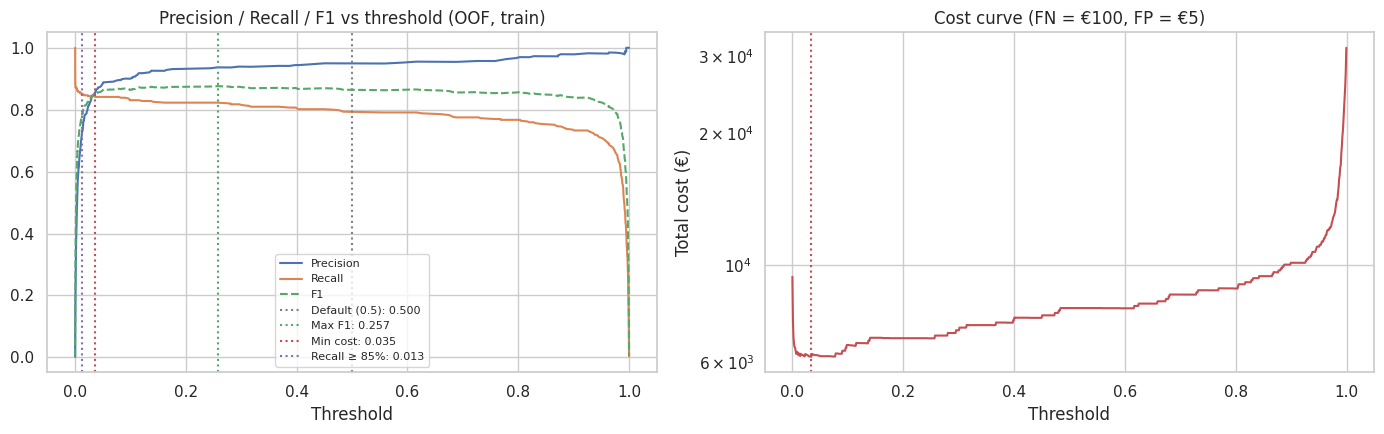

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(thresholds, precision, label="Precision")
axes[0].plot(thresholds, recall, label="Recall")
axes[0].plot(thresholds, f1, label="F1", linestyle="--")
for (name, t), c in zip(candidates.items(), ["gray", "C2", "C3", "C4"]):
    axes[0].axvline(t, color=c, linestyle=":", label=f"{name}: {t:.3f}")
axes[0].set_xlabel("Threshold"); axes[0].set_title("Precision / Recall / F1 vs threshold (OOF, train)")
axes[0].legend(fontsize=8)

axes[1].plot(grid_thr, costs, color="C3")
axes[1].axvline(thr_cost, color="C3", linestyle=":")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Total cost (€)")
axes[1].set_title(f"Cost curve (FN = €{COST_FN}, FP = €{COST_FP})")
axes[1].set_yscale("log")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_threshold_tuning.png", dpi=120, bbox_inches="tight")
plt.show()

**Choose the threshold.** We go with **min cost** because it encodes the actual business trade-off. Change `CHOSEN` if you prefer another strategy — and be ready to explain why in an interview.

In [5]:
CHOSEN = "Min cost"
final_threshold = float(candidates[CHOSEN])
print(f"Chosen strategy: {CHOSEN} -> threshold = {final_threshold:.4f}")

Chosen strategy: Min cost -> threshold = 0.0350


## 3. Final model → evaluate ONCE on the test set

Fit on the full training set, then score the test set at the default 0.5 and at the chosen threshold.

In [6]:
final_pipe = make_experiment(best_config["model"], best_config["technique"], pos_weight=pos_weight)
final_pipe.fit(X_train, y_train)
test_proba = final_pipe.predict_proba(X_test)[:, 1]

test_table = pd.DataFrame([
    {"setting": "Threshold 0.5", **metrics_at_threshold(y_test, test_proba, 0.5)},
    {"setting": f"{CHOSEN} ({final_threshold:.3f})", **metrics_at_threshold(y_test, test_proba, final_threshold)},
]).set_index("setting")
test_table["cost_€"] = test_table["FN"] * COST_FN + test_table["FP"] * COST_FP
test_table.to_csv(REPORTS_DIR / "05_test_results.csv")
test_table[["precision", "recall", "f1", "pr_auc", "roc_auc", "TP", "FP", "FN", "cost_€"]]

,precision,recall,f1,pr_auc,roc_auc,TP,FP,FN,cost_€
setting,,,,,,,,,
Threshold 0.5,0.9726,0.7474,0.8452,0.8322,0.9807,71,2,24,2410
Min cost (0.035),0.8652,0.8105,0.8370,0.8322,0.9807,77,12,18,1860


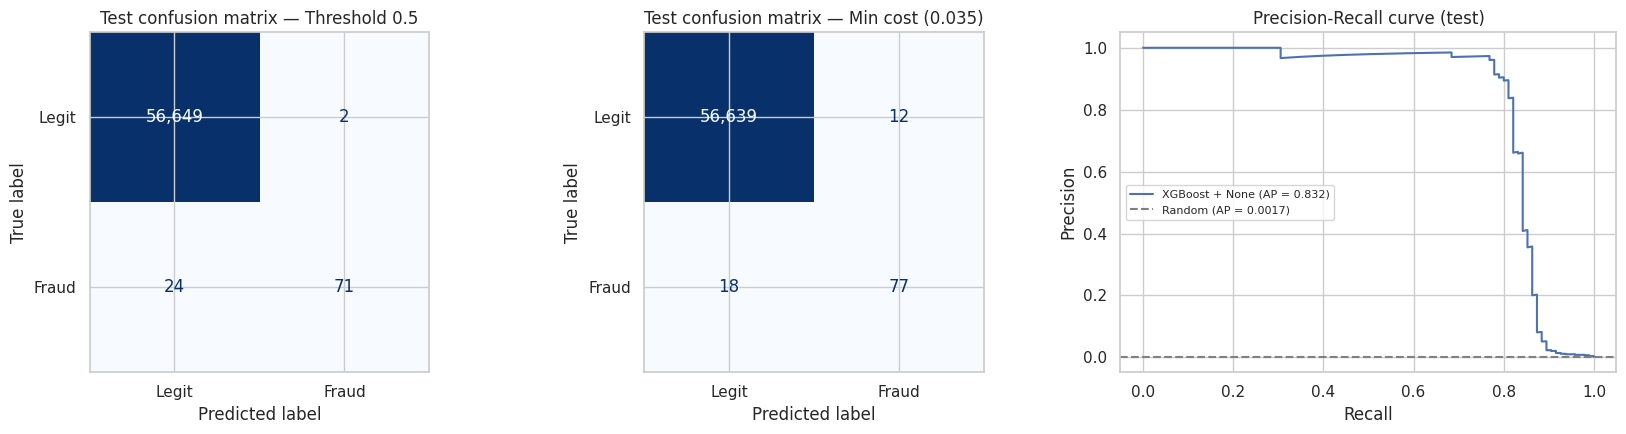

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, t, title in [(axes[0], 0.5, "Threshold 0.5"), (axes[1], final_threshold, f"{CHOSEN} ({final_threshold:.3f})")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, (test_proba >= t).astype(int), display_labels=["Legit", "Fraud"],
        cmap="Blues", colorbar=False, ax=ax, values_format=",d")
    ax.set_title(f"Test confusion matrix — {title}")

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(r, p, color="C0", label=f"{best_config['model']} + {best_config['technique']} (AP = {average_precision_score(y_test, test_proba):.3f})")
axes[2].axhline(y_test.mean(), color="gray", linestyle="--", label=f"Random (AP = {y_test.mean():.4f})")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-Recall curve (test)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_test_evaluation.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Which features drive the model?

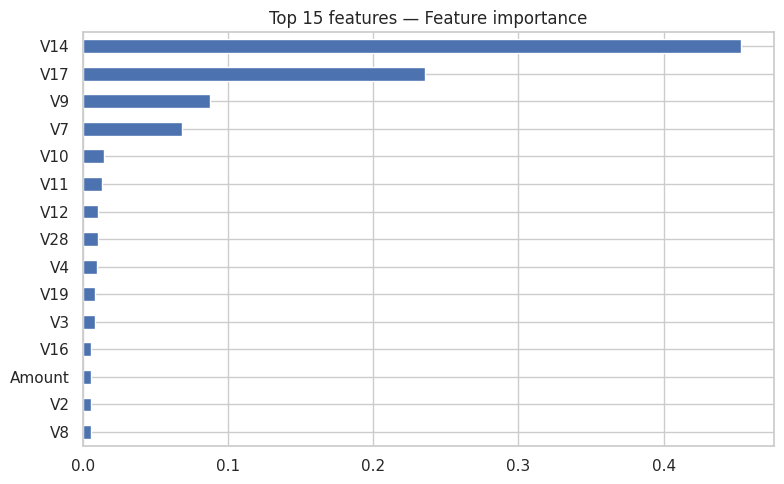

In [8]:
model = final_pipe.named_steps["model"]
feature_names = [n.split("__")[-1] for n in final_pipe.named_steps["prep"].get_feature_names_out()]

if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=feature_names)
    label = "Feature importance"
else:
    imp = pd.Series(np.abs(model.coef_[0]), index=feature_names)
    label = "|coefficient|"

imp.sort_values().tail(15).plot(kind="barh", figsize=(8, 5), color="C0")
plt.title(f"Top 15 features — {label}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Save the model + threshold

In [9]:
joblib.dump({"pipeline": final_pipe, "threshold": final_threshold, "config": best_config},
            MODELS_DIR / "fraudlens_final.joblib")

row = test_table.iloc[1]
print(f"Saved to {MODELS_DIR / 'fraudlens_final.joblib'}\n")
print(f"{best_config['model']} + {best_config['technique']} at threshold {final_threshold:.3f} "
      f"catches {row['recall']:.0%} of fraud ({int(row['TP'])}/{int(row['TP'] + row['FN'])}) "
      f"at {row['precision']:.0%} precision, with {int(row['FP'])} false alarms "
      f"out of {int((y_test == 0).sum()):,} legit test transactions.")

Saved to /tmp/claude-0/-home-claude/25bce366-f326-5915-ae9f-7aeaf528573c/scratchpad/real/models/fraudlens_final.joblib

XGBoost + None at threshold 0.035 catches 81% of fraud (77/95) at 87% precision, with 12 false alarms out of 56,651 legit test transactions.


## Conclusion (fill in from your actual numbers)

- **Final model:** _model + technique_, threshold _x_.
- **Test result:** catches _R%_ of fraud at _P%_ precision (PR-AUC _y_).
- **Key findings:**
  1. Accuracy is meaningless here — a dummy gets 99.8%.
  2. ROC-AUC looked great even for weak models; PR-AUC exposed the real differences.
  3. SMOTE *before* CV inflated scores — resampling belongs inside the pipeline.
  4. Threshold tuning moved the precision/recall balance as much as resampling did, at zero extra cost.
- **Limitations:** only 2 days of data, anonymised features (no domain feature engineering possible), random split rather than time-based, and the cost numbers are assumptions.